# 01 — LEDGAR data and TF–IDF baseline

This notebook establishes a small, reproducible classification baseline for the English LEDGAR clauses. It loads the official train, validation, and test splits, checks class imbalance and exact-text overlap, then fits one TF–IDF + logistic-regression model. It does not search hyperparameters or use the test split for model selection.

**Split protocol.** The published LEDGAR splits are chronological (train, validation, then test), not stratified. We retain them to preserve the benchmark protocol and temporal holdout. The shared dataset loader exposes no contract IDs, so this notebook cannot verify contract-level separation. Exact duplicate text is checked below; near-duplicates are not.

The final test cell is intended to be run once after the validation result has been checked. Restart and run all cells to reproduce.

In [6]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
)

# Support launching either from the project root or from notebooks/.
PROJECT_ROOT = next(
    (parent for parent in [Path.cwd(), *Path.cwd().parents] if (parent / "src" / "data.py").is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Could not locate the project root containing src/data.py")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.config import SEED
from src.data import get_label_names, load_ledgar, to_pandas

np.random.seed(SEED)
print(f"Seed: {SEED}")

Seed: 42


## 1. Load the official data

In [7]:
dataset = load_ledgar()
label_names = get_label_names(dataset)
splits = {name: to_pandas(dataset, name) for name in ("train", "validation", "test")}

split_summary = pd.DataFrame(
    [{"split": name, "rows": len(frame), "unique_labels": frame["label"].nunique()}
     for name, frame in splits.items()]
)
display(split_summary)
print(f"Number of label names: {len(label_names)}")
display(splits["train"].head(3))

,split,rows,unique_labels
0,train,60000,100
1,validation,10000,99
2,test,10000,100


Number of label names: 100


,idx,text,label,label_name
0,0,Except as otherwise set forth in this Debentur...,97,Waivers
1,1,No ERISA Event has occurred or is reasonably e...,39,Erisa
2,2,This Amendment may be executed by one or more ...,26,Counterparts


## 2. Class imbalance and exact-text duplicates

Macro-F1 gives every class equal weight, so the support distribution matters. Duplicate checks use lowercased, whitespace-trimmed exact text only; they are diagnostics, not proof of contract-level independence.

In [8]:
train_counts = (
    splits["train"]["label"].value_counts()
    .reindex(range(len(label_names)), fill_value=0)
    .rename("train_support")
    .rename_axis("label")
    .reset_index()
)
train_counts["label_name"] = train_counts["label"].map(dict(enumerate(label_names)))
print("Most frequent classes in train:")
display(train_counts.sort_values("train_support", ascending=False).head(10))
print("Least frequent classes in train:")
display(train_counts.sort_values("train_support", ascending=True).head(10))
print(f"Train support range: {train_counts['train_support'].min()}–{train_counts['train_support'].max()}")

Most frequent classes in train:


,label,train_support,label_name
47,47,3167,Governing Laws
65,65,2493,Notices
26,26,2427,Counterparts
38,38,2340,Entire Agreements
79,79,1808,Severability
85,85,1469,Survival
2,2,1467,Amendments
7,7,1327,Assignments
41,41,1224,Expenses
89,89,1166,Terms


Least frequent classes in train:


,label,train_support,label_name
14,14,23,Books
8,8,31,Assigns
72,72,47,Qualifications
3,3,106,Anti-Corruption Laws
78,78,118,Sanctions
70,70,125,Powers
94,94,131,Venues
25,25,168,Costs
21,21,175,Consent To Jurisdiction
5,5,178,Approvals


Train support range: 23–3167


In [9]:
def canonical_text(series):
    return series.astype(str).str.strip().str.lower()


duplicate_rows = []
frames_for_overlap = []
for split_name, frame in splits.items():
    normalized = canonical_text(frame["text"])
    duplicate_rows.append({
        "split": split_name,
        "duplicate_text_groups": int(normalized[normalized.duplicated(keep=False)].nunique()),
        "rows_beyond_first_copy": int(normalized.duplicated().sum()),
    })
    frames_for_overlap.append(pd.DataFrame({
        "text_key": normalized,
        "label": frame["label"].to_numpy(),
        "split": split_name,
    }))

all_text = pd.concat(frames_for_overlap, ignore_index=True)
cross_split_groups = (
    all_text.groupby("text_key", sort=False)
    .agg(split_count=("split", "nunique"), label_count=("label", "nunique"), row_count=("label", "size"))
)
cross_split_groups = cross_split_groups[cross_split_groups["split_count"] > 1]
duplicate_rows.append({
    "split": "cross-split",
    "duplicate_text_groups": int(len(cross_split_groups)),
    "rows_beyond_first_copy": int(cross_split_groups["row_count"].sum() - len(cross_split_groups)),
})
display(pd.DataFrame(duplicate_rows))
print("Cross-split exact-text groups with conflicting labels:",
      int((cross_split_groups["label_count"] > 1).sum()))

,split,duplicate_text_groups,rows_beyond_first_copy
0,train,62,64
1,validation,3,3
2,test,13,13
3,cross-split,60,63


Cross-split exact-text groups with conflicting labels: 1


## 3. Fit one fixed TF–IDF + logistic-regression baseline

The vectorizer and classifier are fit on train only. Parameters are fixed in advance: word unigrams/bigrams, `min_df=2`, 
and logistic regression with `C=1`. There is no hyperparameter sweep.

In [10]:
vectorizer = TfidfVectorizer(
    ngram_range=(1, 2),
    min_df=2,
    sublinear_tf=True,
    lowercase=True
)
X_train = vectorizer.fit_transform(splits["train"]["text"])
classifier = LogisticRegression(
    C=1.0,
    max_iter=1_000,
    random_state=SEED,
    solver="lbfgs",
)
classifier.fit(X_train, splits["train"]["label"])
print(f"Train rows: {X_train.shape[0]:,}; TF–IDF features: {X_train.shape[1]:,}")

Train rows: 60,000; TF–IDF features: 173,477


## 4. Validation check

Use validation for development decisions. The test split is not used here.

In [11]:
X_validation = vectorizer.transform(splits["validation"]["text"])
y_validation = splits["validation"]["label"].to_numpy()
validation_pred = classifier.predict(X_validation)
validation_metrics = {
    "split": "validation",
    "macro_f1": f1_score(y_validation, validation_pred, labels=range(len(label_names)), average="macro", zero_division=0),
    "accuracy": accuracy_score(y_validation, validation_pred),
}
display(pd.DataFrame([validation_metrics]))

,split,macro_f1,accuracy
0,validation,0.766555,0.8516


## 5. Final test evaluation — run once

After validation is complete, run this cell once for the final held-out result. It reports macro-F1, accuracy, every class's precision/recall/F1/support, and the confusion matrix. It also saves common-format per-clause test predictions under `results/predictions/` for the paired Legal-BERT comparison; this directory is gitignored, so keep both model prediction files in the same project copy before running `scripts/paired_tests.py`. The test metrics are descriptive only; do not use them to select settings.

,split,macro_f1,accuracy
0,test (2019),0.76246,0.8486


Saved aligned baseline predictions: results/predictions/tfidf-logreg_baseline_20261023_test.parquet


,class,precision,recall,f1-score,support
14,Books,0.000000,0.000000,0.000000,2.0
8,Assigns,0.000000,0.000000,0.000000,4.0
4,Applicable Laws,0.000000,0.000000,0.000000,53.0
72,Qualifications,1.000000,0.200000,0.333333,5.0
59,Miscellaneous,0.628571,0.278481,0.385965,79.0
...,...,...,...,...,...
18,Closings,0.969231,0.984375,0.976744,64.0
96,Waiver Of Jury Trials,0.973214,0.981982,0.977578,111.0
15,Brokers,0.985507,0.971429,0.978417,70.0
26,Counterparts,0.974104,0.997959,0.985887,490.0


Most frequent class confusions:


,true_class,predicted_class,count
0,Applicable Laws,Governing Laws,42
1,Integration,Entire Agreements,28
2,No Waivers,Waivers,28
3,Modifications,Amendments,24
4,Tax Withholdings,Withholdings,24
5,Successors,Binding Effects,21
6,Indemnity,Indemnifications,18
7,Defined Terms,Definitions,18
8,General,Payments,17
9,Taxes,Withholdings,17


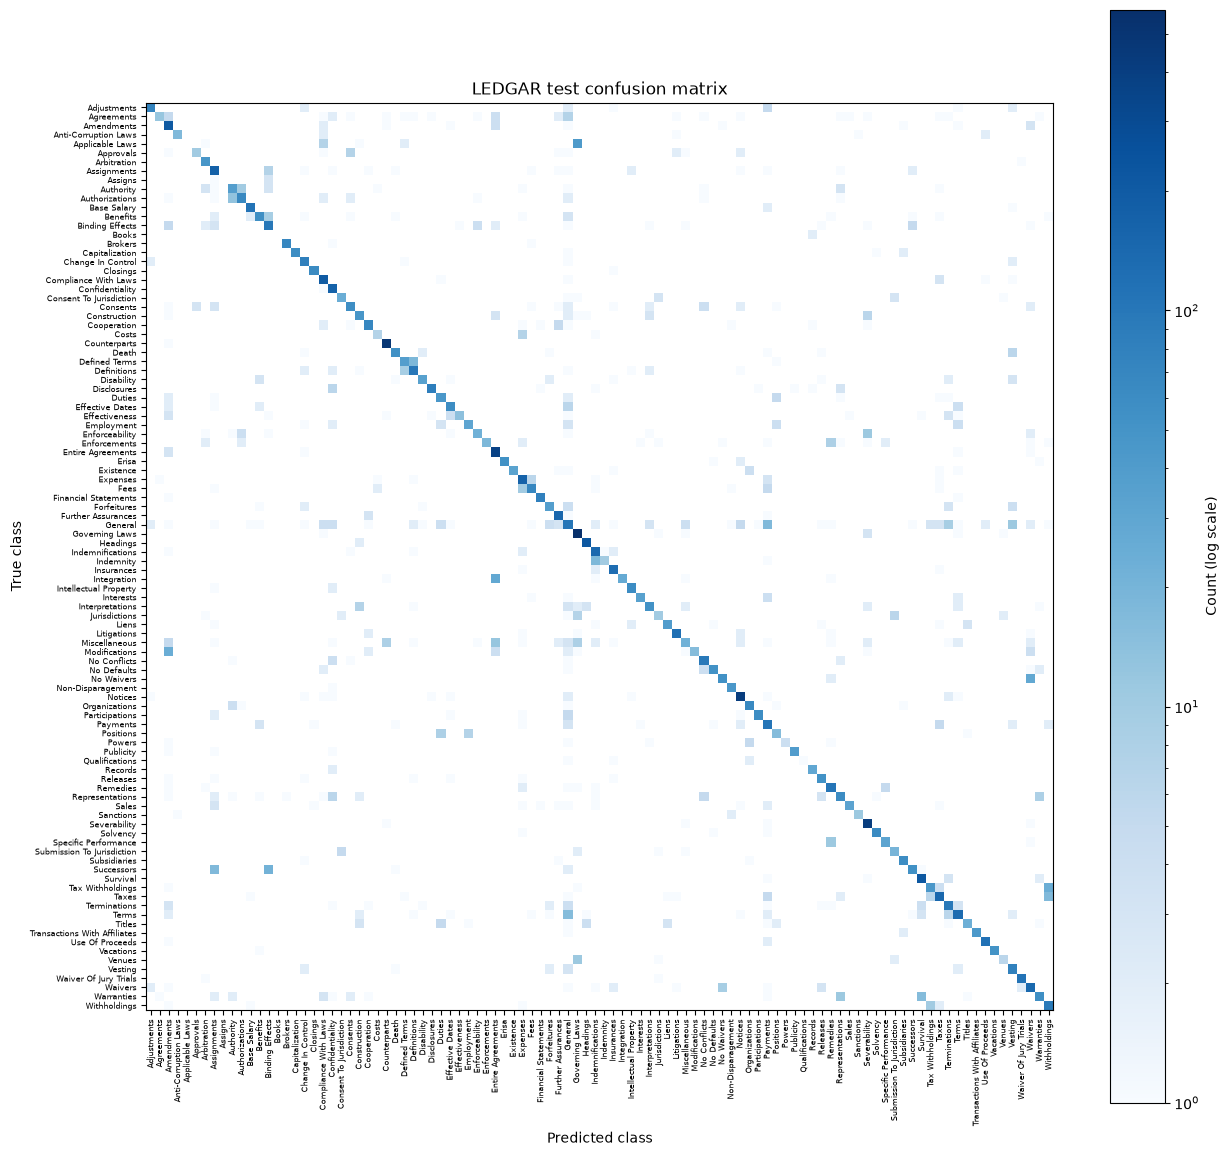

In [13]:
X_test = vectorizer.transform(splits["test"]["text"])
y_test = splits["test"]["label"].to_numpy()
test_pred = classifier.predict(X_test)
test_metrics = {
    "split": "test (2019)",
    "macro_f1": f1_score(y_test, test_pred, labels=range(len(label_names)), average="macro", zero_division=0),
    "accuracy": accuracy_score(y_test, test_pred),
}
display(pd.DataFrame([test_metrics]))

from src.metrics import classification_metrics
from src.utils import save_predictions, save_run

if not np.array_equal(classifier.classes_, np.arange(len(label_names))):
    raise ValueError("TF-IDF probability columns are not in LEDGAR label-id order")

baseline_run_id = "tfidf-logreg_baseline_20261023"
test_probas = classifier.predict_proba(X_test)
baseline_metrics = classification_metrics(y_test, test_pred, num_labels=len(label_names))
save_predictions(baseline_run_id, "test", y_test, test_pred, test_probas)
save_run(
    baseline_run_id,
    {
        "model_name": "TF-IDF + Logistic Regression",
        "variant": "baseline",
        "ngram_range": [1, 2],
        "min_df": 2,
        "sublinear_tf": True,
        "C": 1.0,
        "max_iter": 1_000,
        "n_features": int(X_train.shape[1]),
        "eval_test": True,
        "run_id": baseline_run_id,
    },
    {"test": baseline_metrics},
)
print(f"Saved aligned baseline predictions: results/predictions/{baseline_run_id}_test.parquet")

class_report = classification_report(
    y_test,
    test_pred,
    labels=range(len(label_names)),
    target_names=label_names,
    output_dict=True,
    zero_division=0,
)
per_class_report = pd.DataFrame(class_report).T.iloc[:len(label_names)].copy()
per_class_report.index.name = "class"
per_class_report = per_class_report.reset_index()
display(per_class_report.sort_values(["f1-score", "support"], ascending=[True, True]))

class_ids = np.arange(len(label_names))
cm = confusion_matrix(y_test, test_pred, labels=class_ids)
off_diagonal = cm.copy()
np.fill_diagonal(off_diagonal, 0)
top_errors = [
    {"true_class": label_names[true_id], "predicted_class": label_names[pred_id], "count": int(off_diagonal[true_id, pred_id])}
    for true_id, pred_id in np.dstack(np.unravel_index(np.argsort(off_diagonal.ravel())[::-1], off_diagonal.shape))[0]
    if off_diagonal[true_id, pred_id] > 0
][:10]
print("Most frequent class confusions:")
display(pd.DataFrame(top_errors))

fig, ax = plt.subplots(figsize=(13, 12))
image = ax.imshow(cm, interpolation="nearest", cmap="Blues", norm="log")
fig.colorbar(image, ax=ax, label="Count (log scale)")
ax.set(
    title="LEDGAR test confusion matrix",
    xlabel="Predicted class",
    ylabel="True class",
    xticks=class_ids,
    yticks=class_ids,
)
ax.set_xticklabels(label_names, rotation=90, fontsize=6)
ax.set_yticklabels(label_names, fontsize=6)
fig.tight_layout()
plt.show()

## Interpretation and limits

- Macro-F1 weights each of the 100 clause types equally; compare it with the per-class support and report rather than relying on accuracy alone.
- The official partitions are chronological, not stratified. No contract identifiers are available through the shared loader, and exact-text checks do not establish contract-level separation or detect near-duplicates.
- LEDGAR provides clause text and class labels, not reliable contract-type, party, or jurisdiction metadata. Group-fairness claims require additional verified metadata.
- This baseline classifies English SEC-filed contract clauses. It is not legal advice and must not make autonomous legal or compliance decisions.